# 08. Final test

**Goal.** Score the held-out test groups **once**, for the model chosen in notebook 05 **with the guard layer from notebook 07b**, and compare the result with the success criteria
written in [PROTOCOL.md](PROTOCOL.md) **before** any model was trained.

**Procedure.** For each outer fold: take the settings that notebook 04 chose using only that fold's inner validation groups; refit on all
four non-test groups; predict the rated records of the test group. Pool the 20 predictions (each from a model that never saw that student).

**Discipline.** This notebook is run once. Nothing in notebooks 01-07 depends on its result. Commit count alone and the other baselines are
scored on the same test groups for context only; they do not change the model choice.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"
sys.path.insert(0, str(Path("training").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from common import RESULTS, SEED, SPLITS, environment, group_bootstrap, load, log_run, metrics, paired_diff_bootstrap
from features import FEATURE_SETS, LABEL_SOURCES, add_team_context, feature_matrix, training_set
from final import fit_chosen, make_model, roles_for

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 190)
pd.set_option("display.max_columns", 40)
d = add_team_context(load().set_index("record_id", drop=False))
GOLD = d[d.label_source == "rater"]
choice = json.loads((RESULTS / "model_choice.json").read_text())
print(environment())
print("model chosen in notebook 05:", choice)

{'python': '3.11.14', 'numpy': '2.4.6', 'pandas': '3.0.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'seed': 20261018, 'data_hash': '2a23bdaa674b', 'splits_hash': 'b5793a57b501'}
model chosen in notebook 05: {'model': 'Ridge', 'feature_set': '3 features (chosen)', 'reason': 'no forest or boosting model passes protocol conditions 1-3 against Ridge', 'validation_MAE': 0.0774}


In [2]:
from final import predict_guarded

guard_all = json.loads((RESULTS / "guard_choice.json").read_text())
G = {k: guard_all[k] for k in ("lines_per_commit", "files_per_commit", "zero_rule")}
NO_GUARD = {"lines_per_commit": 0, "files_per_commit": 0, "zero_rule": False}
print("guard layer (notebook 07b):", G)
GROUPS = sorted(d.group.unique())
rows = []
fits = {}
for o in GROUPS:
    m, kind, pick, n_train = fit_chosen(d, o, choice["model"], choice["feature_set"], SEED)
    test = GOLD[GOLD.group == o]
    p = predict_guarded(m, test, choice["feature_set"], kind, G)
    p_raw = predict_guarded(m, test, choice["feature_set"], kind, NO_GUARD)
    fits[o] = (pick, n_train)
    rows += [(o, r, y, pp, cc, ts, pr) for r, y, pp, cc, ts, pr in zip(test.record_id, test.rater_effort, p, test.E_CC, test.team_size, p_raw)]
final = pd.DataFrame(rows, columns=["group", "record_id", "y", "pred", "E_CC", "team_size", "pred_unguarded"])
print(len(final), "test predictions from", len(GROUPS), "models (with the guard layer)")
pd.DataFrame({o: {"label source": v[0]["label_source"], "weight": v[0]["weight"], "settings": json.dumps(v[0]["params"]), "training rows": v[1]} for o, v in fits.items()}).T

guard layer (notebook 07b): {'lines_per_commit': 100, 'files_per_commit': 20, 'zero_rule': True}
20 test predictions from 5 models (with the guard layer)


,label source,weight,settings,training rows
A,rated only,1.0,"{""alpha"": 3.1622776601683795}",13
B,rated only,1.0,"{""alpha"": 10.0}",16
C,rated only,1.0,"{""alpha"": 10.0}",16
D,rated only,1.0,"{""alpha"": 1.0}",17
E,rated only,1.0,"{""alpha"": 3.1622776601683795}",18


## 1. Baselines on the same test groups (for context)

In [3]:
def baseline_predictions(o):
    train = d[(d.source == "real") & (d.group != o) & (d.label_source == "rater")]
    test = GOLD[GOLD.group == o]
    cc_max = d[(d.source == "real") & (d.group != o)].E_CC.max()
    out = {"always predict the mean": np.full(len(test), train.rater_effort.mean()),
           "commits (normalised)": np.clip(np.log1p(test.E_CC) / np.log1p(cc_max), 0, 1).to_numpy()}
    b, a = np.polyfit(np.log1p(train.E_CC), train.rater_effort, 1)
    out["commits (linear)"] = np.clip(a + b * np.log1p(test.E_CC), 0, 1).to_numpy()
    return test, out

bl = {}
for o in GROUPS:
    test, out = baseline_predictions(o)
    for name, p in out.items():
        bl.setdefault(name, []).extend(zip([o] * len(test), test.record_id, test.rater_effort, p, test.E_CC))
base = {n: pd.DataFrame(v, columns=["group", "record_id", "y", "pred", "E_CC"]) for n, v in bl.items()}
base[f"{choice['model']} ({choice['feature_set']}) + guard"] = final[["group", "record_id", "y", "pred", "E_CC"]]
base[f"{choice['model']} ({choice['feature_set']}), no guard"] = final[["group", "record_id", "y", "pred_unguarded", "E_CC"]].rename(columns={"pred_unguarded": "pred"})
rows = []
for n, g in base.items():
    mm = metrics(g.y, g.pred)
    lo, hi = group_bootstrap(g.y.to_numpy(), g.pred.to_numpy(), g.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=2000)
    act = g[g.E_CC > 0]
    rows.append({"model": n, "MAE": mm["MAE"], "MAE 95% CI": f"{lo:.3f}-{hi:.3f}", "RMSE": mm["RMSE"], "bias": mm["bias"], "Pearson": mm["pearson"], "Spearman": mm["spearman"],
                 "R2": mm["R2"], "calib slope": mm["calib_slope"], "band exact": mm["band_exact"], "band within 1": mm["band_within_1"], "MAE active": float(np.abs(act.pred - act.y).mean())})
test_table = pd.DataFrame(rows).set_index("model").sort_values("MAE")
test_table.round(3)

,MAE,MAE 95% CI,RMSE,bias,Pearson,Spearman,R2,calib slope,band exact,band within 1,MAE active
model,,,,,,,,,,,
commits (normalised),0.054,0.024-0.072,0.073,-0.022,0.962,0.953,0.915,1.059,0.60,1.0,0.063
commits (linear),0.055,0.025-0.079,0.076,0.000,0.952,0.931,0.906,1.010,0.65,1.0,0.063
Ridge (3 features (chosen)) + guard,0.069,0.040-0.090,0.096,-0.010,0.931,0.931,0.850,1.153,0.55,1.0,0.081
"Ridge (3 features (chosen)), no guard",0.077,0.048-0.093,0.103,0.006,0.921,0.913,0.831,1.169,0.55,1.0,0.087
always predict the mean,0.239,0.176-0.324,0.285,-0.013,-0.739,-0.646,-0.310,-4.005,0.15,0.5,0.204


## 2. The result for the chosen model, in full

MAE 0.069  (95% CI 0.040-0.090)   RMSE 0.096   median abs error 0.044
Pearson 0.931 (95% CI 0.756-0.978)   Spearman 0.931   Kendall 0.811   R2 0.850   CCC 0.909
ICC(2,1) 0.914   ICC(3,1) 0.910   bias -0.010   calibration slope 1.15 intercept -0.05
within 0.1: 70%   rubric band exact 55%   within one band 100%   weighted kappa 0.77


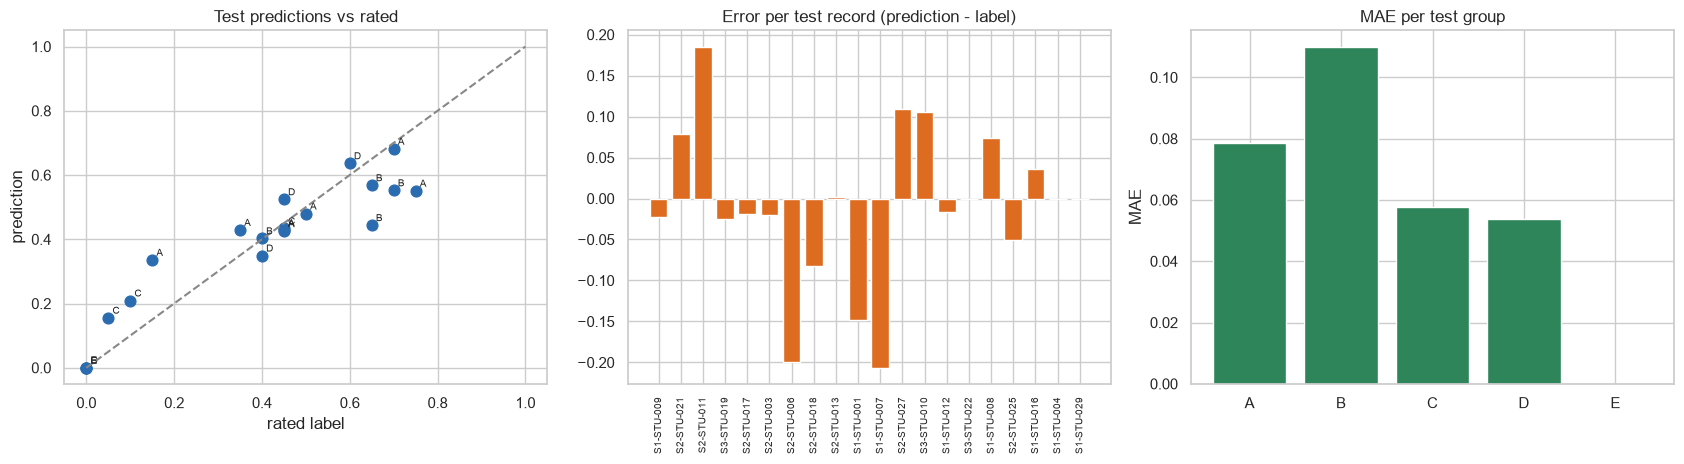

In [4]:
m = metrics(final.y, final.pred)
lo, hi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.mean(np.abs(p - y)), n=5000)
rlo, rhi = group_bootstrap(final.y.to_numpy(), final.pred.to_numpy(), final.group.to_numpy(), lambda y, p: np.corrcoef(y, p)[0, 1], n=5000)
print(f"MAE {m['MAE']:.3f}  (95% CI {lo:.3f}-{hi:.3f})   RMSE {m['RMSE']:.3f}   median abs error {m['MedAE']:.3f}")
print(f"Pearson {m['pearson']:.3f} (95% CI {rlo:.3f}-{rhi:.3f})   Spearman {m['spearman']:.3f}   Kendall {m['kendall']:.3f}   R2 {m['R2']:.3f}   CCC {m['CCC']:.3f}")
print(f"ICC(2,1) {m['ICC2_1']:.3f}   ICC(3,1) {m['ICC3_1']:.3f}   bias {m['bias']:.3f}   calibration slope {m['calib_slope']:.2f} intercept {m['calib_intercept']:.2f}")
print(f"within 0.1: {m['within_0.1']:.0%}   rubric band exact {m['band_exact']:.0%}   within one band {m['band_within_1']:.0%}   weighted kappa {m['band_qwk']:.2f}")
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
axes[0].scatter(final.y, final.pred, s=60, color="#2b6cb0")
for r in final.itertuples():
    axes[0].annotate(r.group, (r.y, r.pred), fontsize=7, xytext=(3, 3), textcoords="offset points")
axes[0].plot([0, 1], [0, 1], "--", color="#888"); axes[0].set(title="Test predictions vs rated", xlabel="rated label", ylabel="prediction")
axes[1].bar(final.record_id.str.replace(r"^T\d+-", "", regex=True), (final.pred - final.y), color="#dd6b20")
axes[1].set(title="Error per test record (prediction - label)"); axes[1].tick_params(axis="x", rotation=90, labelsize=7)
per_group = final.groupby("group").apply(lambda g: np.abs(g.pred - g.y).mean(), include_groups=False)
axes[2].bar(per_group.index, per_group.values, color="#2f855a"); axes[2].set(title="MAE per test group", ylabel="MAE")
plt.tight_layout()
plt.show()

## 3. Against the protocol's success criteria

Criteria exactly as written in `PROTOCOL.md` before any model was trained.

In [5]:
commits = base["commits (normalised)"].sort_values("record_id").reset_index(drop=True)
mine = final.sort_values("record_id").reset_index(drop=True)
glo, ghi = paired_diff_bootstrap(mine.y.to_numpy(), commits.pred.to_numpy(), mine.pred.to_numpy(), mine.group.to_numpy(), n=5000)
mae_c, mae_m = float(np.abs(commits.pred - commits.y).mean()), float(np.abs(mine.pred - mine.y).mean())
act = final[final.E_CC > 0]
mae_act = float(np.abs(act.pred - act.y).mean())

def row(name, value, minimum, target, ok_min, ok_target):
    return {"criterion": name, "result": value, "minimum (works)": minimum, "target": target, "meets minimum": ok_min, "meets target": ok_target}

criteria = pd.DataFrame([
    row("MAE", f"{m['MAE']:.3f}", "<= 0.11", "<= 0.08", m["MAE"] <= 0.11, m["MAE"] <= 0.08),
    row("Pearson", f"{m['pearson']:.3f}", ">= 0.80", ">= 0.90", m["pearson"] >= 0.80, m["pearson"] >= 0.90),
    row("Spearman", f"{m['spearman']:.3f}", ">= 0.80", ">= 0.85", m["spearman"] >= 0.80, m["spearman"] >= 0.85),
    row("Beats commit count alone", f"gain {mae_c - mae_m:+.3f} (95% CI {glo:.3f} to {ghi:.3f})", "interval excludes 0", "and >= 10% lower MAE",
        glo > 0, (glo > 0) and (mae_m <= 0.9 * mae_c)),
    row("Bias", f"{m['bias']:+.3f}", "within +-0.05", "within +-0.03", abs(m["bias"]) <= 0.05, abs(m["bias"]) <= 0.03),
    row("Calibration slope", f"{m['calib_slope']:.2f}", "0.7 - 1.3", "0.8 - 1.2", 0.7 <= m["calib_slope"] <= 1.3, 0.8 <= m["calib_slope"] <= 1.2),
    row("Rubric bands within one", f"{m['band_within_1']:.0%}", ">= 85%", ">= 90%", m["band_within_1"] >= 0.85, m["band_within_1"] >= 0.90),
    row("Rubric bands exact", f"{m['band_exact']:.0%}", "-", ">= 50%", True, m["band_exact"] >= 0.50),
    row("MAE, records with activity", f"{mae_act:.3f}", "<= 0.12", "<= 0.10", mae_act <= 0.12, mae_act <= 0.10),
]).set_index("criterion")
criteria

,result,minimum (works),target,meets minimum,meets target
criterion,,,,,
MAE,0.069,<= 0.11,<= 0.08,True,True
Pearson,0.931,>= 0.80,>= 0.90,True,True
Spearman,0.931,>= 0.80,>= 0.85,True,True
Beats commit count alone,gain -0.015 (95% CI -0.052 to 0.011),interval excludes 0,and >= 10% lower MAE,False,False
Bias,-0.010,within +-0.05,within +-0.03,True,True
Calibration slope,1.15,0.7 - 1.3,0.8 - 1.2,True,True
Rubric bands within one,100%,>= 85%,>= 90%,True,True
Rubric bands exact,55%,-,>= 50%,True,True
"MAE, records with activity",0.081,<= 0.12,<= 0.10,True,True


In [6]:
inv = pd.read_csv(RESULTS / "runs.csv")
inv = inv[inv.notebook == "07_robustness_and_gaming"].tail(1)
print("invariants (notebook 07):", inv[["zero_commits", "monotone", "spam_ceiling"]].to_dict("records")[0] if len(inv) else "not run")
works = bool(criteria["meets minimum"].all())
target = bool(criteria["meets target"].all())
print("meets every MINIMUM criterion:", works, "| meets every TARGET criterion:", target)
for name, row_ in test_table.iterrows():
    log_run("08_final_test", name, "outer test groups, pooled (20 records)", {"MAE": round(row_.MAE, 4), "RMSE": round(row_.RMSE, 4), "pearson": round(row_.Pearson, 4),
                                                                              "spearman": round(row_.Spearman, 4), "bias": round(row_.bias, 4), "MAE_active": round(row_["MAE active"], 4)})
final.to_csv(RESULTS / "final_test_predictions.csv", index=False)
criteria.to_csv(RESULTS / "final_test_criteria.csv")

invariants (notebook 07): {'zero_commits': False, 'monotone': True, 'spam_ceiling': False}
meets every MINIMUM criterion: False | meets every TARGET criterion: False


## 4. Reading the results

**The model:** Ridge on three features (commits, capped lines, files), trained on rated records only, with the guard layer from notebook 07b.
Scored once on the held-out test groups: 20 rated records, each predicted by a model that never saw that student.

| Metric (test) | Result | 95% interval (resampling groups) |
|---|---|---|
| MAE | **0.069** | 0.040 - 0.090 |
| RMSE | 0.096 | |
| Pearson / Spearman | **0.931** / 0.931 | 0.756 - 0.978 (Pearson) |
| ICC(2,1) / ICC(3,1) | 0.914 / 0.910 | |
| Bias | -0.010 | |
| Calibration slope | 1.15 | |
| Rubric band: exact / within one | 55% / 100% | |

**Against the protocol's criteria (written before any training)**

- **Met, including every target:** MAE (0.069 vs target 0.08), Pearson (0.93 vs 0.90), Spearman (0.93 vs 0.85), bias (-0.010), calibration slope
  (1.15), rubric bands (100% within one, 55% exact), and MAE on students with activity (0.081 vs 0.10).
- **Not met: beating commit count alone.** The gain over commits-normalised is **-0.015** (95% interval -0.052 to +0.011): the model is not
  better, and the interval cannot exclude that it is worse. Commit count alone scores 0.054 on the same test groups.

By the protocol's own definition ("meeting every minimum means the model works"), the Effort model **does not yet work**, because it does not
beat the simplest baseline. All other criteria are met comfortably, but several of them are easy: the protocol's absolute targets were set
before we knew that commit count alone reaches MAE 0.054.

**The guard layer was worth it.** On the test groups the guarded model (0.069) beats the same model without the guard (0.077), as on
validation. (The line "invariants (notebook 07)" printed above refers to the model *without* the guard, which fails; the guarded model
passes all three in notebook 07b.)

**What can honestly be said**

1. A model built from the proposal's features reproduces the rubric ratings of held-out students to within about 0.07 (correlation 0.93).
2. A parameter-free commit count does as well or slightly better on this label set, so these 20 labels cannot show the extra features and
   models add value. The learning curves (notebook 04) say more labels would help.
3. The accuracy of both is high partly because the ratings were built from the same commit evidence; a rubric separating work quality
   from volume is what would let richer models separate themselves.
4. The robustness work found something accuracy did not: the model and the commit count baseline can both be gamed, and a rule layer
   in front of the model fixes it without losing accuracy.

Saved: `training/results/final_test_predictions.csv`, `final_test_criteria.csv`.